In [1]:
import pandas as pd

In [2]:
df = pd.read_csv('food_clean.csv')
df['Inspection Date'] = pd.to_datetime(df['Inspection Date'])
df.shape

(126787, 20)

In [3]:
df.columns

Index(['Inspection ID', 'DBA Name', 'AKA Name', 'License #', 'Facility Type',
       'Risk', 'Address', 'City', 'State', 'Zip', 'Inspection Date',
       'Inspection Type', 'Results', 'Violations', 'Latitude', 'Longitude',
       'Location', 'Year', 'Fail', 'Period'],
      dtype='str')

In [4]:
def risk_number(r):
    if r == 'Risk 1 (High)':
        return 1
    elif r == 'Risk 2 (Medium)':
        return 2
    elif r == 'Risk 3 (Low)':
        return 3
    else:
        return 0

df['Risk_Num'] = df['Risk'].apply(risk_number)
df['Risk_Num'].value_counts()

Risk_Num
1    98246
2    21563
3     6977
0        1
Name: count, dtype: int64

In [25]:
df.head()

,Inspection ID,DBA Name,AKA Name,License #,Facility Type,Risk,Address,City,State,Zip,...,Inspection Type,Results,Violations,Latitude,Longitude,Location,Year,Fail,Period,Risk_Num
0,2569129,CRUMBL COOKIES,CRUMBL COOKIES,2882090.0,Restaurant,Risk 2 (Medium),2321 N LINCOLN AVE,CHICAGO,IL,60614.0,...,License Re-Inspection,Pass,NaN,41.924208,-87.646818,"(41.924207920242395, -87.6468181094676)",2022,0,Post,2
1,2569114,STARBUCKS COFFEE #20797,STARBUCKS,2341106.0,Restaurant,Risk 2 (Medium),3640 N WESTERN AVE,CHICAGO,IL,60618.0,...,Canvass,Pass,57. ALL FOOD EMPLOYEES HAVE FOOD HANDLER TRAIN...,41.947947,-87.688440,"(41.94794732437379, -87.68844043392538)",2022,0,Post,2
2,2569125,LITTLE EXPLORERS LEARNING ACADEMY INC.,LITTLE EXPLORERS LEARNING ACADEMY INC.,2608949.0,Daycare (2 - 6 Years),Risk 1 (High),6636-6642 W ARCHER AVE,CHICAGO,IL,60638.0,...,License,Pass,NaN,41.792333,-87.788146,"(41.79233314231487, -87.78814644431729)",2022,0,Post,1
3,2569122,BOSTON MARKET #2520,BOSTON MARKET #2520,86324.0,Restaurant,Risk 1 (High),3020 N ASHLAND AVE,CHICAGO,IL,60657.0,...,Canvass,Fail,"1. PERSON IN CHARGE PRESENT, DEMONSTRATES KNOW...",41.936721,-87.668703,"(41.9367209159054, -87.66870256330071)",2022,1,Post,1
4,2569126,TODD APPEL BAR AND COCKTAIL,TODD APPEL BAR AND COCKTAIL,2589615.0,Grocery Store,Risk 2 (Medium),5868 N LINCOLN AVE,CHICAGO,IL,60659.0,...,Canvass,Pass,NaN,41.988060,-87.703704,"(41.98805967591636, -87.70370445181302)",2022,0,Post,2


In [30]:
df['License #'].nunique()

25572

In [31]:
df.groupby('License #')['Risk_Num'].value_counts().unstack()

Risk_Num,0,1,2,3
License #,,,,
2.0,NaN,9.0,NaN,NaN
9.0,NaN,8.0,NaN,NaN
40.0,NaN,10.0,NaN,NaN
62.0,NaN,9.0,NaN,NaN
99.0,NaN,3.0,NaN,NaN
...,...,...,...,...
4067203.0,NaN,1.0,NaN,NaN
4067403.0,NaN,1.0,NaN,NaN
4073655.0,NaN,1.0,NaN,NaN


In [32]:
df.groupby('License #')['Risk_Num'].value_counts().unstack().isna().sum()

Risk_Num
0    25571
1     9213
2    19945
3    21907
dtype: int64

In [43]:
df2 = df.groupby('License #')['Risk_Num'].value_counts().unstack()
license_with_more_than_one_risk = df2[df2.isna().sum(axis=1) < 3]
license_with_more_than_one_risk.shape

(79, 4)

In [45]:
license_with_more_than_one_risk

Risk_Num,0,1,2,3
License #,,,,
980.0,NaN,NaN,9.0,2.0
7077.0,NaN,1.0,2.0,NaN
12173.0,NaN,3.0,1.0,NaN
15956.0,NaN,11.0,1.0,NaN
22624.0,NaN,NaN,1.0,5.0
...,...,...,...,...
2657906.0,NaN,3.0,1.0,NaN
2671483.0,NaN,1.0,NaN,1.0
2745150.0,NaN,2.0,NaN,1.0


In [68]:
df[df['License #'] == 2748901][['License #','Facility Type','Risk','DBA Name','AKA Name','Inspection Date']]

,License #,Facility Type,Risk,DBA Name,AKA Name,Inspection Date
21947,2748901.0,Restaurant,Risk 3 (Low),WISHFUL GROCERS,WISHFUL GROCERS,2021-06-01
24549,2748901.0,Shared Kitchen,Risk 1 (High),CLOUD KITCHENS,CLOUD KITCHENS,2021-03-30


In [44]:
25572+79

25651

In [34]:
25572*4-9213-19945-21907-25571

25652

In [8]:
df[df['Risk_Num'] == 3]

,Inspection ID,DBA Name,AKA Name,License #,Facility Type,Risk,Address,City,State,Zip,...,Inspection Type,Results,Violations,Latitude,Longitude,Location,Year,Fail,Period,Risk_Num
17,2569120,MEME GROCERY STORE,MEME GROCERY STORE,2872598.0,Grocery Store,Risk 3 (Low),5467 W CHICAGO AVE,CHICAGO,IL,60651.0,...,Complaint Re-Inspection,Pass,NaN,41.894759,-87.763322,"(41.89475899998373, -87.76332224650253)",2022,0,Post,3
47,2569070,KEDZIE GROCERY,KEDZIE GROCERY,2882190.0,Grocery Store,Risk 3 (Low),4617-4619 N KEDZIE AVE,CHICAGO,IL,60625.0,...,License,Pass,51. PLUMBING INSTALLED; PROPER BACKFLOW DEVICE...,41.965237,-87.708227,"(41.96523653337399, -87.70822685098508)",2022,0,Post,3
60,2569025,HEAVEN ELEVEN,HEAVEN ELEVEN,2882187.0,Grocery Store,Risk 3 (Low),6016 W NORTH AVE,CHICAGO,IL,60639.0,...,License,Pass,49. NON-FOOD/FOOD CONTACT SURFACES CLEAN - Com...,41.909359,-87.775987,"(41.90935850137094, -87.77598653362747)",2022,0,Post,3
61,2569039,EVOLVE BY HUDSON,EVOLVE BY HUDSON T5 M14/15,2886525.0,Grocery Store,Risk 3 (Low),11601 W TOUHY AVE,CHICAGO,IL,60666.0,...,License,Pass,NaN,42.008751,-87.906874,"(42.00875076599798, -87.90687413400109)",2022,0,Post,3
65,2569041,BP AMOCO,BP AMOCO,1887541.0,Grocery Store,Risk 3 (Low),3611 N HARLEM AVE,CHICAGO,IL,60634.0,...,Canvass Re-Inspection,Pass,10. ADEQUATE HANDWASHING SINKS PROPERLY SUPPLI...,41.945629,-87.806871,"(41.94562902171779, -87.80687135285183)",2022,0,Post,3
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
126706,1515588,WALGREENS #05034,WALGREENS #05034,2360134.0,Grocery Store,Risk 3 (Low),6315 S KEDZIE AVE,CHICAGO,IL,60629.0,...,License,Pass,"35. WALLS, CEILINGS, ATTACHED EQUIPMENT CONSTR...",41.778421,-87.702976,"(41.778421336390466, -87.70297605813722)",2015,0,Pre,3
126755,1441674,CVS/ PHARMACY #8732,CVS/ PHARMACY #8732,1695286.0,Grocery Store,Risk 3 (Low),2053 N MILWAUKEE AVE,CHICAGO,IL,60647.0,...,Canvass Re-Inspection,Pass,"35. WALLS, CEILINGS, ATTACHED EQUIPMENT CONSTR...",41.918629,-87.690123,"(41.918629408691885, -87.69012302262763)",2015,0,Pre,3
126759,1408287,CVS/PHARMACY #1493,CVS/PHARMACY #1493,1910535.0,Grocery Store,Risk 3 (Low),5205 N BROADWAY,CHICAGO,IL,60640.0,...,Canvass Re-Inspection,Pass,36. LIGHTING: REQUIRED MINIMUM FOOT-CANDLES OF...,41.976529,-87.659724,"(41.97652938043876, -87.65972361874651)",2015,0,Pre,3
126766,1515580,HADAYA,HADAYA,2374001.0,Grocery Store,Risk 3 (Low),4635-37 N KEDZIE AVE,CHICAGO,IL,60625.0,...,License,Fail,2. FACILITIES TO MAINTAIN PROPER TEMPERATURE -...,41.965725,-87.708244,"(41.96572453795366, -87.70824350196105)",2015,1,Pre,3


In [73]:
df.groupby('Zip')['License #'].nunique().sort_values(ascending=False)

Zip
60647.0    1022
60614.0    1003
60611.0     896
60657.0     871
60607.0     833
           ... 
60035.0       1
60047.0       1
60706.0       1
60714.0       1
90067.0       1
Name: License #, Length: 95, dtype: int64

<Axes: xlabel='Zip'>

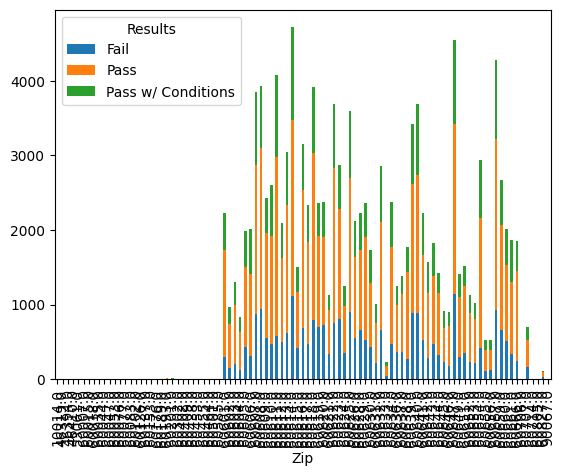

In [77]:
df.groupby('Zip')['Results'].value_counts().unstack().plot.bar(stacked=True)

<Axes: xlabel='Zip'>

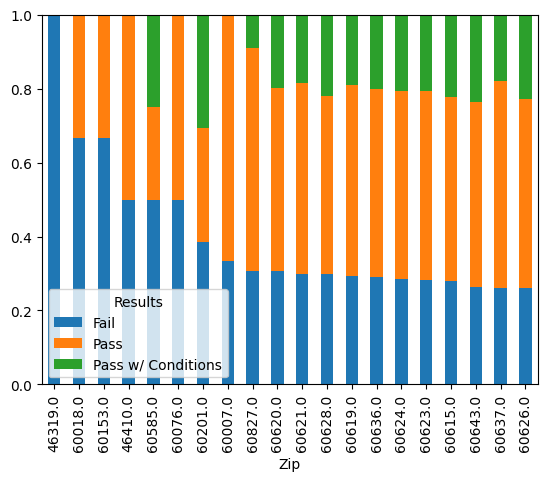

In [86]:
df.groupby('Zip')['Results'].value_counts(normalize=True).unstack().sort_values('Fail',ascending=False).head(20).plot.bar(stacked=True)

In [87]:
df[df['Zip']==46319]

,Inspection ID,DBA Name,AKA Name,License #,Facility Type,Risk,Address,City,State,Zip,...,Inspection Type,Results,Violations,Latitude,Longitude,Location,Year,Fail,Period,Risk_Num
47154,2301197,ICE CREAM ON WHEELS,ICE CREAM ON WHEELS,2678115.0,Mobile Food Dispenser,Risk 3 (Low),2011 N GRIFFIN BLVD,GRIFFITH,IN,46319.0,...,License,Fail,5. PROCEDURES FOR RESPONDING TO VOMITING AND D...,NaN,NaN,NaN,2019,1,Post,3


In [88]:
import matplotlib.pyplot as plt

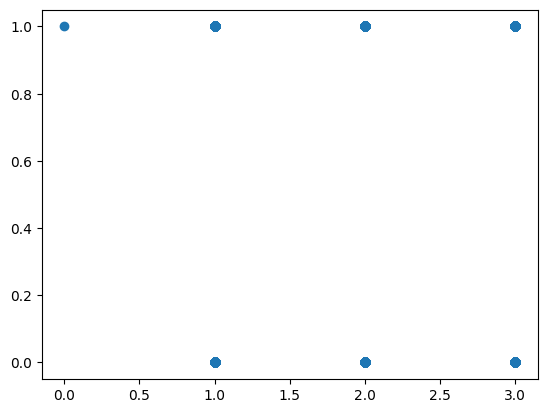

In [89]:
plt.scatter(df['Risk_Num'], df['Results'].apply(lambda x: 1 if x == 'Fail' else 0))

In [100]:
df1 = df[df['Risk_Num'] == 1]

In [103]:
df1.head()

,Inspection ID,DBA Name,AKA Name,License #,Facility Type,Risk,Address,City,State,Zip,...,Inspection Type,Results,Violations,Latitude,Longitude,Location,Year,Fail,Period,Risk_Num
2,2569125,LITTLE EXPLORERS LEARNING ACADEMY INC.,LITTLE EXPLORERS LEARNING ACADEMY INC.,2608949.0,Daycare (2 - 6 Years),Risk 1 (High),6636-6642 W ARCHER AVE,CHICAGO,IL,60638.0,...,License,Pass,NaN,41.792333,-87.788146,"(41.79233314231487, -87.78814644431729)",2022,0,Post,1
3,2569122,BOSTON MARKET #2520,BOSTON MARKET #2520,86324.0,Restaurant,Risk 1 (High),3020 N ASHLAND AVE,CHICAGO,IL,60657.0,...,Canvass,Fail,"1. PERSON IN CHARGE PRESENT, DEMONSTRATES KNOW...",41.936721,-87.668703,"(41.9367209159054, -87.66870256330071)",2022,1,Post,1
5,2569133,MYSTIC ROGUE,MYSTIC ROGUE,2708621.0,Restaurant,Risk 1 (High),6064-6070 N NORTHWEST HWY,CHICAGO,IL,60631.0,...,Canvass,Fail,2. CITY OF CHICAGO FOOD SERVICE SANITATION CER...,41.991482,-87.797812,"(41.99148225930689, -87.7978116394828)",2022,1,Post,1
6,2569124,JAMAICA JERK CHOICE,JAMAICA JERK CHOICE,2840736.0,Restaurant,Risk 1 (High),1934 E 95TH ST,CHICAGO,IL,60617.0,...,License,Pass w/ Conditions,"3. MANAGEMENT, FOOD EMPLOYEE AND CONDITIONAL E...",41.722565,-87.576429,"(41.722564843819455, -87.57642879596078)",2022,0,Post,1
9,2569119,ST BERNARD HOSPITAL & HEALTH CENTER,ST BERNARD HOSPITAL & HEALTH CENTER,2204276.0,Hospital,Risk 1 (High),326 W 64TH ST,CHICAGO,IL,60621.0,...,Canvass Re-Inspection,Pass,47. FOOD & NON-FOOD CONTACT SURFACES CLEANABLE...,41.778215,-87.633464,"(41.77821515610851, -87.63346442603714)",2022,0,Post,1


In [104]:
df2 = df[df['Risk_Num'] == 2]

In [106]:
df2['Risk_Num'].corr(df1['Fail'])

nan

In [107]:
df['Risk_Num'].corr(df['Fail'])

np.float64(0.017802152949525786)

<Axes: ylabel='Frequency'>

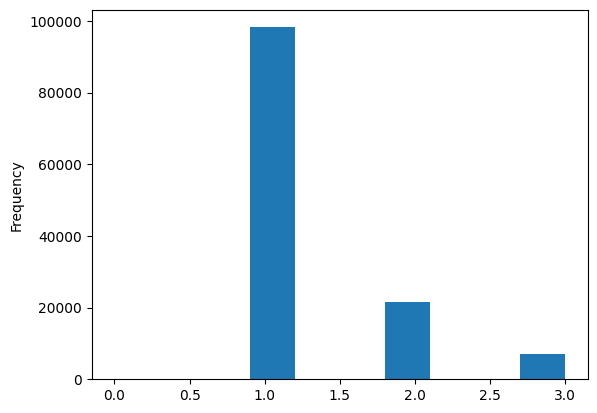

In [109]:
df['Risk_Num'].plot.hist()

In [110]:
df['Risk_Num'].value_counts()

Risk_Num
1    98246
2    21563
3     6977
0        1
Name: count, dtype: int64

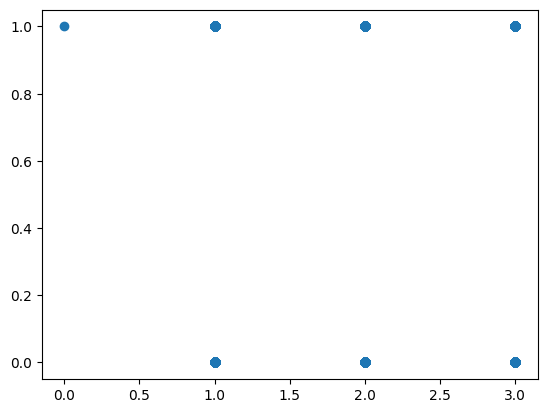

In [108]:
plt.scatter(df['Risk_Num'], df['Fail'])